# All labs

> Recalibration, a refit of the head, fine-tuning and PLSR on every ring-trial instrument

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fastcore.test import *
from soilspecdata.datasets.ringtrial import load_ringtrial
from ossl_rt_transfer.data import rt_path, near_dup_groups, load_instruments
from soilspecdl.all import predict
from ossl_rt_transfer.pretrain import load_pretrained, rt_wns, model_dir
from ossl_rt_transfer.finetune import rt_xy, soil_folds, cv_plsr, cv_cnn, paired_test, cached, repeat_scores, group_errors
from ossl_rt_transfer.recalibrate import cv_recal

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


The cells that read the ring-trial data are marked `#| rtdata`. The outputs on this page come from a local run.

`08_recalibrate` found, on KSSL and IAEA, that fine-tuning for K is a linear recalibration of the zero-shot predictions, while for clay it re-weights the pooled features. This notebook tests both findings on all 21 instruments, with the corrections that need no training:

- `zero-shot`: the pretrained model as it is.
- `bias` and `slope and bias`: linear corrections of the zero-shot predictions.
- `head refit`: a ridge refit of the last layer on the pooled features.
- `PLSR`: PLSR trained only on the instrument's soils, as in `07_finetune`.

The last sections add full fine-tuning and the block-4 ridge of `07_finetune`, which both train the network.

Each method is fitted on the training folds of each instrument, with the folds of `07_finetune`. The starting model is the unaugmented 80-epoch model for each property. The results of KSSL and IAEA come from the saved results of `07_finetune` and `08_recalibrate`.

## Data

In [ ]:
#| rtdata
rt = load_ringtrial(rt_path())
groups = pd.Series(near_dup_groups(rt['KSSL']), index=rt['KSSL'].sample_ids)
inst_info = load_instruments()[['cluster', 'manufacturer', 'model', 'accessory']]
props, insts, start = ['potassium_cmolkg', 'clay_perc'], list(rt.keys()), 'snv_ep80'
folds = soil_folds(groups)
preds = []
for p in props:
    m = load_pretrained(f'ossl_{p}_{start}')
    for i in insts:
        X, y, ids = rt_xy(rt[i], p)
        tag = dict(instrument=i, property=p, start='not augmented 80')
        rc = cached(f'recal_{i}_{p}_{start}', lambda: cv_recal(m, X, y, ids, folds))
        p0 = pd.Series(predict(m, X, rt_wns).ravel(), index=ids)
        zs = rc[rc.method == 'bias'].assign(method='zero-shot', pred=lambda d: p0[d.sample_id].values)
        pl = cached(f'plsr_{i}_{p}', lambda: cv_plsr(X, y, ids, groups, folds))
        preds += [d.assign(**tag) for d in (zs, rc, pl)]
methods = ['zero-shot', 'bias', 'slope and bias', 'head refit', 'PLSR']
preds = pd.concat(preds, ignore_index=True).query('method in @methods')
test_eq(preds.instrument.nunique(), 21)
test_eq(preds.groupby(['instrument', 'property', 'method', 'repeat']).size().max(), 69)

## Scores

Mean R² over the 10 repeats, for each instrument, with the instrument's cluster in Safanelli et al. (2023). For K, R² is on the `log1p` scale. The rows are sorted by cluster, then by the R² of PLSR:

In [ ]:
#| rtdata
keys = ['instrument', 'property', 'method']
scores = repeat_scores(preds, keys).groupby(keys).mean()
def table(col, p):
    t = scores[col].xs(p, level='property').unstack('method')[methods]
    t = inst_info[['cluster', 'manufacturer']].join(t, how='right')
    return t.sort_values(['cluster', 'PLSR'], ascending=[True, False])
table('R²', 'potassium_cmolkg').round(2)

,cluster,manufacturer,zero-shot,bias,slope and bias,head refit,PLSR
instrument,,,,,,,
UWisc_fine,1.0,Bruker,0.03,-0.00,0.32,0.34,0.46
UIUC,2.0,Thermo Fisher,-2.74,-1.25,0.06,-0.14,0.42
IAEA_aug2022,2.0,Thermo Fisher,-2.57,-0.31,0.44,0.46,0.40
Lesotho,2.0,PerkinElmer,-1.46,-1.42,-0.07,0.24,0.38
OSU,2.0,Thermo Fisher,-0.73,0.11,0.40,0.58,0.22
UGhent,2.0,Agilent,-1.39,-0.39,0.45,0.55,0.21
Argonne,2.0,PerkinElmer,0.23,0.33,0.49,0.66,0.15
USP,3.0,Bruker,-1.03,0.15,0.59,0.45,0.29
Woodwell_alpha,3.0,Bruker,-0.46,-0.12,0.37,0.41,0.27


In [ ]:
#| rtdata
table('R²', 'clay_perc').round(2)

,cluster,manufacturer,zero-shot,bias,slope and bias,head refit,PLSR
instrument,,,,,,,
UWisc_fine,1.0,Bruker,0.47,0.55,0.58,0.78,0.70
Argonne,2.0,PerkinElmer,0.72,0.71,0.71,0.82,0.71
UIUC,2.0,Thermo Fisher,-0.01,-0.05,0.18,0.22,0.58
OSU,2.0,Thermo Fisher,0.49,0.48,0.50,0.76,0.55
IAEA_aug2022,2.0,Thermo Fisher,-2.73,-0.12,0.21,0.58,0.45
UGhent,2.0,Agilent,0.35,0.46,0.63,0.73,0.40
Lesotho,2.0,PerkinElmer,-0.24,-0.17,0.04,0.35,-0.20
Woodwell_vertex,3.0,Bruker,0.72,0.71,0.71,0.89,0.71
ETH_alpha_2,3.0,Bruker,0.61,0.60,0.62,0.75,0.69


## Zero-shot calibration

As in `08_recalibrate`, a linear regression of the targets on the zero-shot predictions over all soils. `r²` is the most R² a linear correction can reach on these soils, and the slope is 1 for a calibrated model:

In [ ]:
#| rtdata
def calib(d):
    b, a = np.polyfit(d.pred, d.y, 1)
    return pd.Series({'slope': b, 'offset': d.pred.mean() - d.y.mean(), 'r²': np.corrcoef(d.pred, d.y)[0, 1]**2})
z0 = preds[(preds.method == 'zero-shot') & (preds.repeat == 0)]
cal = z0.groupby(['property', 'instrument'])[['pred', 'y']].apply(calib)
cal.unstack('property').round(2)

slope                   ...        r²                 
property        clay_perc potassium_cmolkg  ... clay_perc potassium_cmolkg
instrument                                  ...                           
Agrocares            0.85             0.61  ...      0.70             0.53
Argonne              0.89             0.64  ...      0.73             0.52
CSU_IL               0.83             0.69  ...      0.87             0.55
ETH_alpha_1          0.65             0.55  ...      0.51             0.57
ETH_alpha_2          0.82             0.62  ...      0.64             0.52
ETH_vertex           0.81             0.70  ...      0.83             0.51
Hokudai              0.85             0.49  ...      0.61             0.56
IAEA_aug2022         0.47             0.44  ...      0.28             0.47
KSSL                 0.86             0.56  ...      0.86             0.63
LandCare             0.76             0.66  ...      0.84             0.50
Lesotho              0.40            -0.04  ...      0.10             0.00
MSU                  0.82             0.66  ...      0.84             0.59
OSU                  0.83             0.54  ...      0.52             0.44
Rothamsted           0.86             0.70  ...      0.78             0.47
Scion                0.90             0.53  ...      0.87             0.60
UGhent               0.66             0.43  ...      0.65             0.50
UIUC                 0.50             0.24  ...      0.26             0.13
USP                  0.53             0.54  ...      0.32             0.61
UWisc_fine           0.81             0.51  ...      0.60             0.36
Woodwell_alpha       0.88             0.48  ...      0.80             0.42
Woodwell_vertex      0.93             0.62  ...      0.73             0.53

[21 rows x 6 columns]

## Paired tests

For each instrument, the squared error on the model scale is averaged over the repeats and the soils of each near-duplicate group, as in `07_finetune`. The table counts the instruments where method A has the smaller error on more than half of the groups with p < 0.05 (`A wins`), and where B does (`B wins`). The p-values are not corrected for the number of tests:

In [ ]:
#| rtdata
ge = group_errors(preds, groups, keys)
pairs = [('slope and bias', 'PLSR'), ('head refit', 'PLSR'), ('head refit', 'slope and bias'), ('slope and bias', 'bias')]
tests = pd.DataFrame({(p, a, b, i): paired_test(ge.loc[(i, p, a)], ge.loc[(i, p, b)])
                      for p in props for a, b in pairs for i in insts}).T
tests.index.names = ['property', 'A', 'B', 'instrument']
sig = tests.p < 0.05
counts = pd.DataFrame({'A wins': (sig & (tests.A_better > 0.5)), 'B wins': (sig & (tests.A_better < 0.5))}).groupby(['property', 'A', 'B']).sum()
counts

A wins  B wins
property         A              B                             
clay_perc        head refit     PLSR                11       1
                                slope and bias      19       0
                 slope and bias PLSR                 1       8
                                bias                 2       0
potassium_cmolkg head refit     PLSR                16       1
                                slope and bias       8       0
                 slope and bias PLSR                 6       2
                                bias                15       0

## R² by instrument

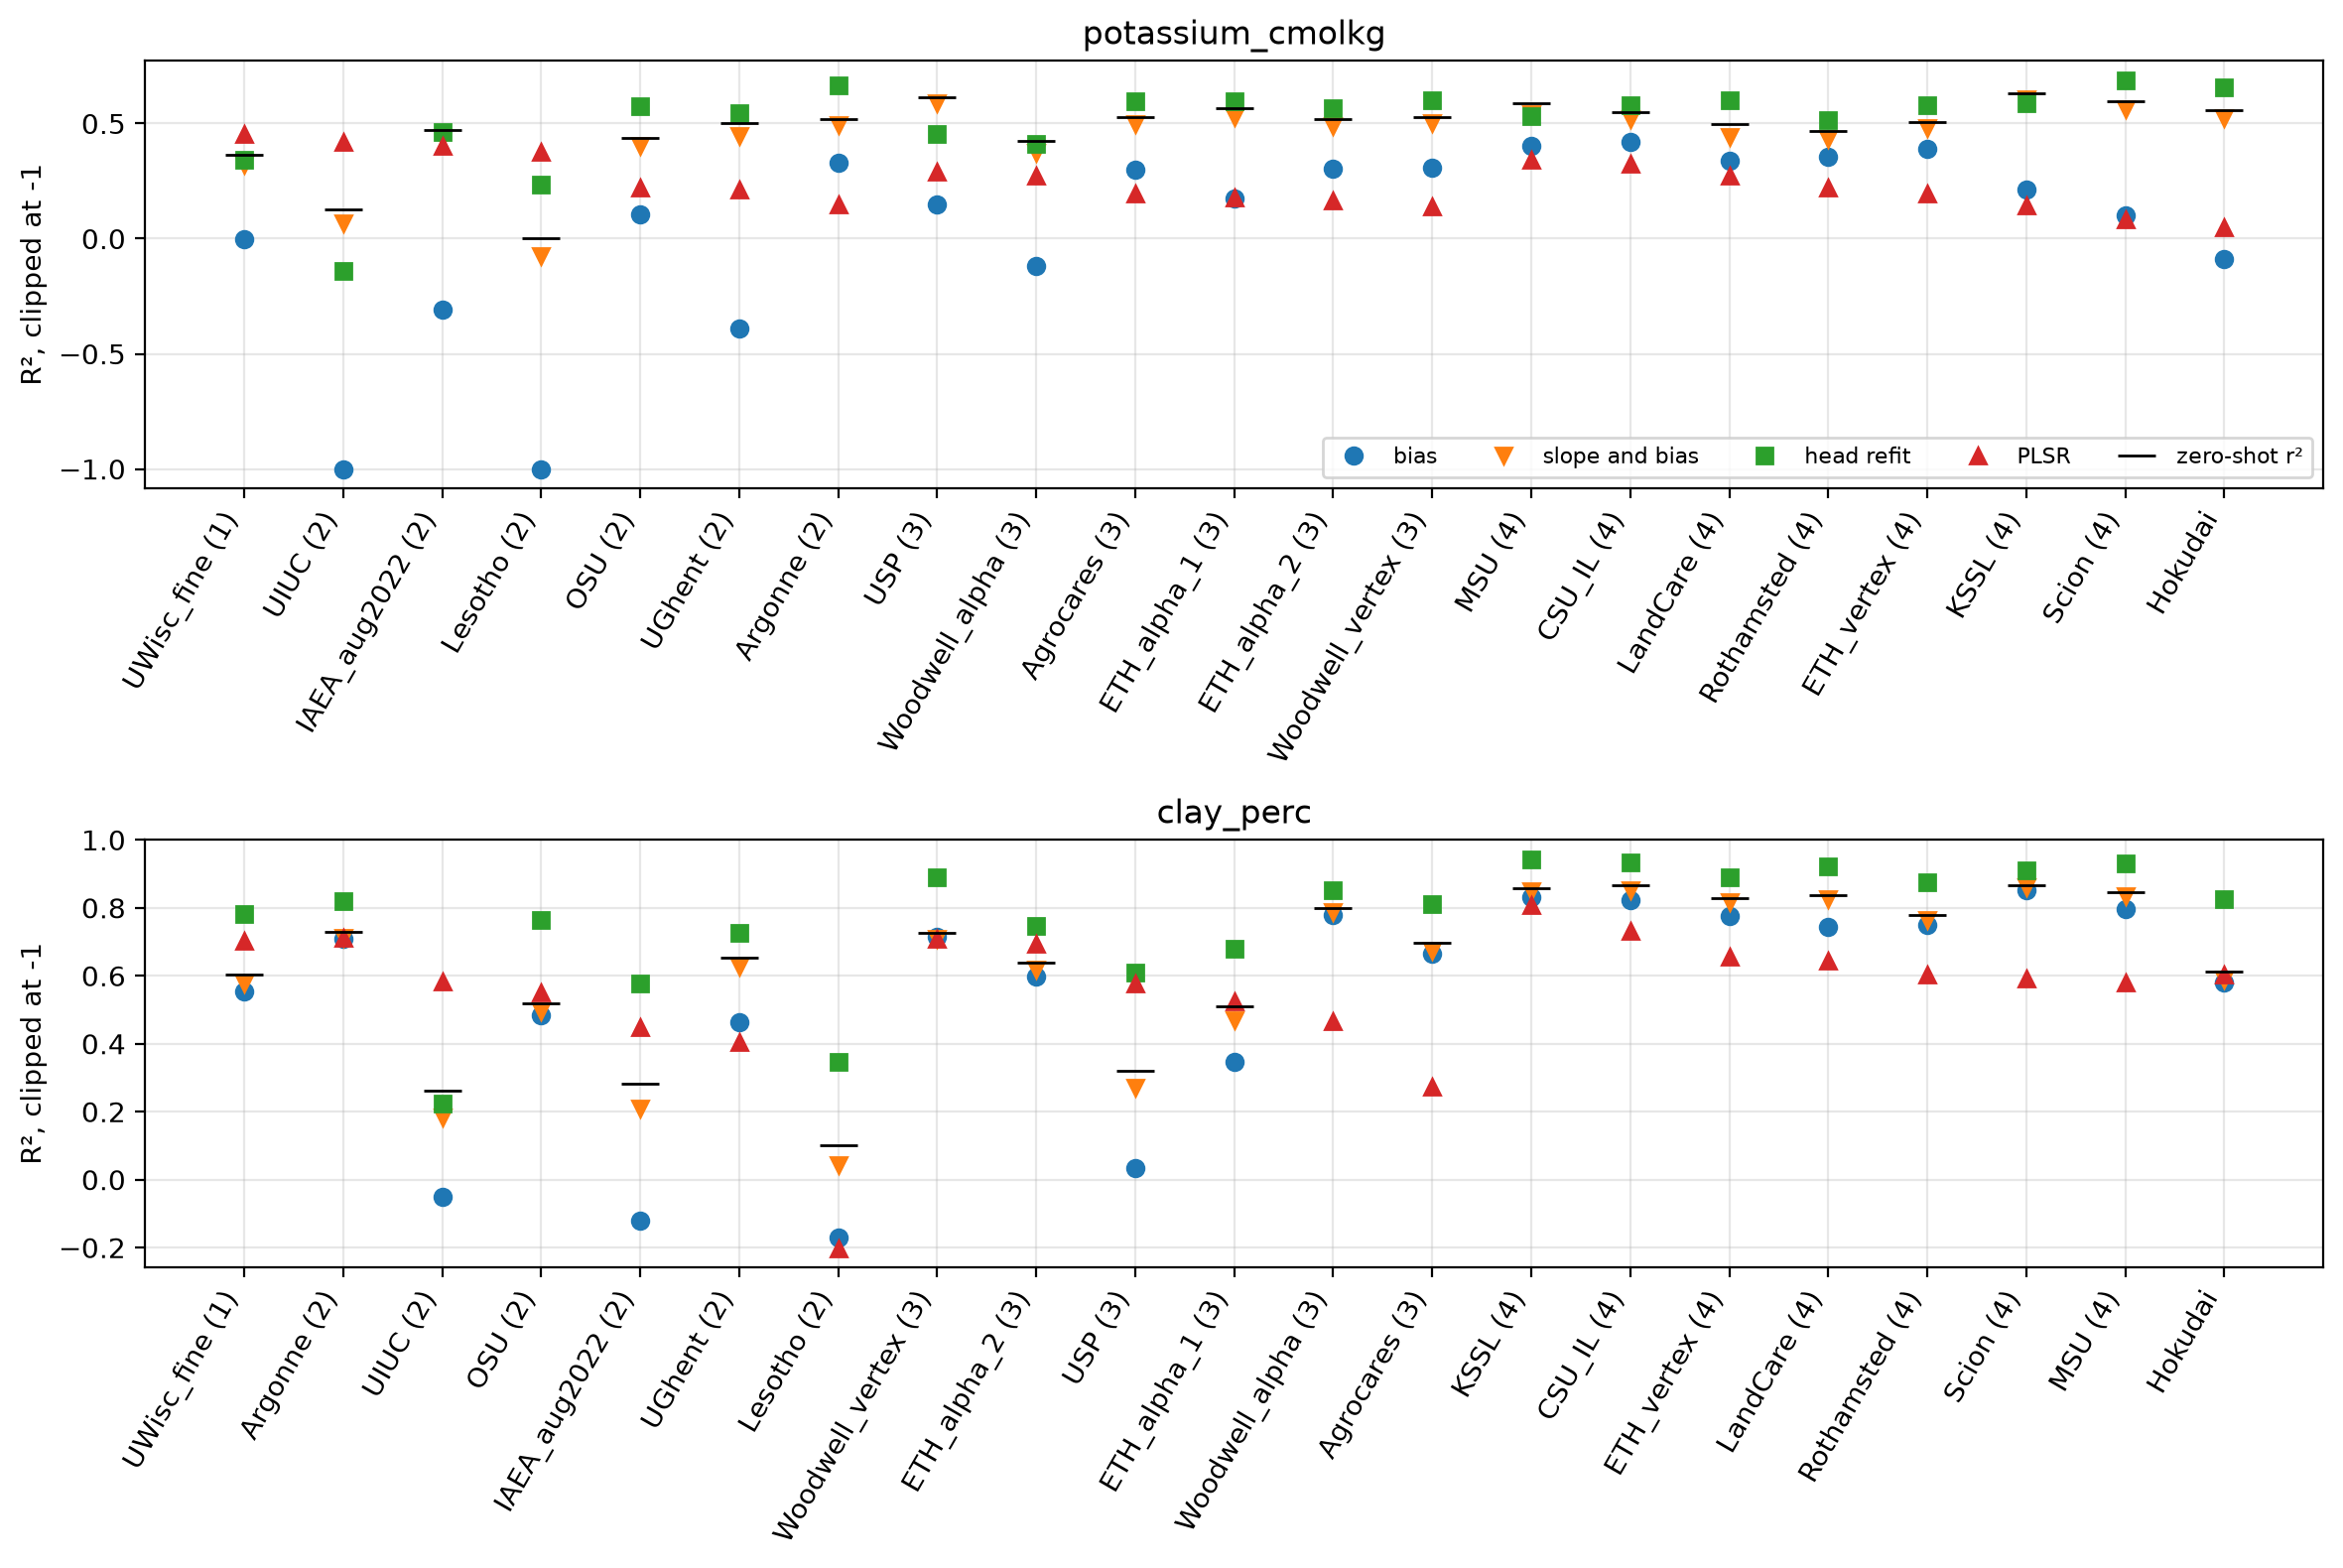

In [ ]:
#| rtdata
fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
for ax, p in zip(axs, props):
    t = table('R²', p)
    x = np.arange(len(t))
    for m, mk in zip(methods[1:], 'ovs^'):
        ax.plot(x, t[m].clip(lower=-1), mk, label=m)
    ax.plot(x, cal.loc[p, 'r²'][t.index], 'k_', ms=14, label='zero-shot r²')
    ax.set_xticks(x, [f'{i} ({c:.0f})' if c == c else i for i, c in zip(t.index, t.cluster)], rotation=60, ha='right')
    ax.set_title(p); ax.set_ylabel('R², clipped at -1'); ax.grid(alpha=0.3)
axs[0].legend(ncol=5, fontsize=8)
plt.tight_layout()

## Results without training

**K: the zero-shot predictions are too spread out on every lab.** The slope of the targets on the zero-shot predictions is 0.43 to 0.70 on 19 of the 21 instruments, including all the Bruker HTS-XT instruments of cluster 4 (0.53 to 0.70). The two exceptions are Lesotho and UIUC, where the predictions barely correlate with the targets (r² 0.00 and 0.13). The over-dispersion does not depend on the instrument, so it comes from the model or the soils. The predictions are also too high on 19 instruments, by up to 0.36 on the `log1p` scale. The largest offsets are on IAEA (0.36), Hokudai (0.32), UIUC (0.30), USP (0.26), UGhent (0.24) and OSU (0.22).

**K: a linear correction is not always enough.** A slope and bias raises the median R² from 0.17 (bias only) to 0.49, and beats the bias alone on 15 instruments. Refitting the head raises it further, to 0.58. It beats the slope and bias on 8 instruments (Argonne, ETH_vertex, LandCare, Lesotho, OSU, Rothamsted, Scion and Hokudai) and never loses. So the finding of `08_recalibrate` that K needs only a linear recalibration holds on KSSL and IAEA, but not on these 8 instruments. There, re-weighting the pooled features adds to the linear correction. The head refit beats PLSR on 16 instruments and loses only on UIUC. PLSR reaches a median R² of only 0.22 for K.

**Clay: the linear correction is a bias correction, and the head refit adds most.** The slope adds to the bias on only 2 instruments. The bias corrections are large on the HTS-XT instruments of cluster 4: their zero-shot offsets are +2.5 to +8.8 points, like the KSSL bias. Refitting the head raises the median R² from 0.67 to 0.82. It beats the slope and bias on 19 instruments and PLSR on 11, and loses to PLSR only on UIUC. With the head refit, R² is 0.87 to 0.94 on cluster 4, 0.61 to 0.89 on cluster 3 and 0.22 to 0.82 on cluster 2.

**UIUC and Lesotho.** On both, the zero-shot predictions barely correlate with the targets, for K and for clay (r² 0.00 to 0.26). On UIUC, PLSR does better than any correction of the pretrained model: R² 0.42 for K and 0.58 for clay, against -0.14 and 0.22 for the head refit. The UIUC spectra therefore hold information that the pretrained features miss. On Lesotho every method is poor, and PLSR for clay reaches -0.20, so the spectra themselves seem to hold little information. UIUC is a Thermo Fisher Nicolet, like IAEA and OSU, and Lesotho is a PerkinElmer. Both are in cluster 2.

## Fine-tuning

Full fine-tuning and the block-4 ridge of `07_finetune`, from the same starting model, on the same folds. The number of epochs is the one chosen for this starting model in `07_finetune`, by grouped cross-validation on KSSL:

In [ ]:
#| rtdata
n_epochs = {p: int(cached(f'epochs_{p}', None)['not augmented 80'].idxmin()) for p in props}
ft_preds = []
for p in props:
    m = load_pretrained(f'ossl_{p}_{start}')
    for i in insts:
        X, y, ids = rt_xy(rt[i], p)
        def run():
            pc, hc = cv_cnn(m, X, y, ids, folds, n_epochs[p])
            hc.to_csv(model_dir()/'finetune'/f'hist_{i}_{p}_{start}.csv')
            return pc
        ft_preds.append(cached(f'cnn_{i}_{p}_{start}', run).assign(instrument=i, property=p, start='not augmented 80'))
ft_preds = pd.concat(ft_preds, ignore_index=True).query("method != 'zero-shot'")
methods_ft = methods[:4] + ['ridge block 4', 'fine-tuned', 'PLSR']
preds_ft = pd.concat([preds, ft_preds], ignore_index=True)
scores_ft = repeat_scores(preds_ft, keys).groupby(keys).mean()
n_epochs

{'potassium_cmolkg': 200, 'clay_perc': 30}

Mean R² over the 10 repeats, with the squared zero-shot correlation `r²`, the most a linear correction can reach:

In [ ]:
#| rtdata
def table_ft(p):
    t = scores_ft['R²'].xs(p, level='property').unstack('method')[methods_ft]
    t = inst_info[['cluster']].join(t, how='right').join(cal.loc[p, 'r²'].rename('zero-shot r²'))
    return t.sort_values(['cluster', 'fine-tuned'], ascending=[True, False])
table_ft('potassium_cmolkg').round(2)

,cluster,zero-shot,bias,slope and bias,head refit,ridge block 4,fine-tuned,PLSR,zero-shot r²
instrument,,,,,,,,,
UWisc_fine,1.0,0.03,-0.00,0.32,0.34,0.52,0.54,0.46,0.36
UGhent,2.0,-1.39,-0.39,0.45,0.55,0.45,0.66,0.21,0.50
OSU,2.0,-0.73,0.11,0.40,0.58,0.18,0.63,0.22,0.44
Argonne,2.0,0.23,0.33,0.49,0.66,0.01,0.63,0.15,0.52
IAEA_aug2022,2.0,-2.57,-0.31,0.44,0.46,0.44,0.51,0.40,0.47
UIUC,2.0,-2.74,-1.25,0.06,-0.14,0.42,0.48,0.42,0.13
Lesotho,2.0,-1.46,-1.42,-0.07,0.24,0.32,0.31,0.38,0.00
ETH_alpha_2,3.0,-0.33,0.30,0.49,0.56,0.39,0.66,0.17,0.52
Agrocares,3.0,0.01,0.30,0.50,0.60,0.25,0.65,0.20,0.53


In [ ]:
#| rtdata
table_ft('clay_perc').round(2)

,cluster,zero-shot,bias,slope and bias,head refit,ridge block 4,fine-tuned,PLSR,zero-shot r²
instrument,,,,,,,,,
UWisc_fine,1.0,0.47,0.55,0.58,0.78,0.64,0.81,0.70,0.60
Argonne,2.0,0.72,0.71,0.71,0.82,0.72,0.86,0.71,0.73
OSU,2.0,0.49,0.48,0.50,0.76,0.75,0.78,0.55,0.52
UGhent,2.0,0.35,0.46,0.63,0.73,0.62,0.77,0.40,0.65
UIUC,2.0,-0.01,-0.05,0.18,0.22,0.63,0.70,0.58,0.26
IAEA_aug2022,2.0,-2.73,-0.12,0.21,0.58,0.69,0.69,0.45,0.28
Lesotho,2.0,-0.24,-0.17,0.04,0.35,0.39,0.54,-0.20,0.10
Woodwell_vertex,3.0,0.72,0.71,0.71,0.89,0.66,0.89,0.71,0.73
Agrocares,3.0,0.67,0.66,0.67,0.81,0.68,0.84,0.27,0.70


Counts of instruments where fine-tuning has the smaller error on more than half of the groups with p < 0.05 (`A wins`), and where the other method does (`B wins`):

In [ ]:
#| rtdata
ge_ft = group_errors(preds_ft, groups, keys)
pairs_ft = [('fine-tuned', 'slope and bias'), ('fine-tuned', 'head refit'), ('fine-tuned', 'ridge block 4'), ('fine-tuned', 'PLSR')]
tests_ft = pd.DataFrame({(p, a, b, i): paired_test(ge_ft.loc[(i, p, a)], ge_ft.loc[(i, p, b)])
                         for p in props for a, b in pairs_ft for i in insts}).T
tests_ft.index.names = ['property', 'A', 'B', 'instrument']
sig = tests_ft.p < 0.05
pd.DataFrame({'A wins': sig & (tests_ft.A_better > 0.5), 'B wins': sig & (tests_ft.A_better < 0.5)}).groupby(['property', 'A', 'B']).sum()

A wins  B wins
property         A          B                             
clay_perc        fine-tuned PLSR                16       0
                            head refit           6       1
                            ridge block 4        3       0
                            slope and bias      15       0
potassium_cmolkg fine-tuned PLSR                17       0
                            head refit           8       0
                            ridge block 4       13       0
                            slope and bias      14       0

## Results of fine-tuning

**Fine-tuning has the highest median R² for both properties.** For K it reaches 0.63, against 0.58 for the head refit, 0.49 for slope and bias and 0.22 for PLSR. For clay it reaches 0.83, against 0.82 for the head refit and 0.59 for PLSR. It beats PLSR on 17 instruments for K and 16 for clay, and never loses to it.

**K: fine-tuning adds a small, consistent gain over the head refit.** R² is 0.54 to 0.74 on 19 instruments, 0.48 on UIUC and 0.31 on Lesotho. The median gain over the best correction without training or the block-4 ridge is 0.05 R², and the largest is 0.18, on Woodwell_alpha. Fine-tuning beats the slope and bias on 14 instruments and the head refit on 8 (Agrocares, Hokudai, KSSL, Rothamsted, UGhent, UIUC, UWisc_fine and Woodwell_alpha), and loses to neither. The block-4 ridge is poor for K on most instruments (median 0.25), but does well on three of the instruments where the zero-shot predictions correlate least with the targets: UIUC (0.42), UWisc_fine (0.52) and Lesotho (0.32). On Lesotho, PLSR (0.38) is above fine-tuning (0.31), but the difference is not significant.

**Clay: fine-tuning matters where the pretrained features fail.** On most instruments, the head refit is as good as fine-tuning, and the median difference is 0.00. The head refit is higher on the HTS-XT instruments of cluster 4, for example KSSL (0.94 against 0.90), MSU (0.93 against 0.90) and LandCare (0.92 against 0.88). KSSL is the only instrument where fine-tuning loses significantly. Fine-tuning beats the head refit on 6 instruments: ETH_alpha_1, ETH_alpha_2, IAEA, Lesotho, UGhent and UIUC. The largest gains are on the four instruments with the lowest zero-shot r² (0.10 to 0.32): UIUC (0.22 to 0.70), Lesotho (0.35 to 0.54), IAEA (0.58 to 0.69) and USP (0.61 to 0.69). The block-4 ridge reaches the R² of fine-tuning on IAEA (0.69) and most of it on UIUC (0.63), but not on Lesotho (0.39) or USP (0.60).

**What this suggests.** Where the pooled features of the pretrained model already carry the property, a refit of the head is enough, and fine-tuning adds little. Where they do not, as for clay on UIUC, Lesotho, IAEA and USP, the inner layers must change. The scores suggest this but do not test it. The questions on where fine-tuning acts, in the roadmap, would test it.

**Limits.** All the results use one starting model, the unaugmented 80-epoch model, and about 63 training soils per fold. The number of epochs was chosen by cross-validation on KSSL, so the KSSL result is slightly optimistic. PLSR trained only on the instrument's soils is a weak baseline: a model trained on OSSL with the instrument's soils added was not tested. The p-values of the 168 paired tests are not corrected for the number of tests.